# Leading-run effect on ln kappa: fresh-rule replication and single-flip mutants

## Question and why it matters
Among chaotic generalised Langton's ants, the amplitude kappa in dA/dt = c·kappa·P/A varies from rule to rule. A post hoc decode (`../2026-10-kappa-prefix-decode`) found that the length of the opening run of identical letters (`lead`) predicts ln kappa beyond ln A(22). This experiment asks two things: (1) does that replicate on fresh rules stratified by lead, at fixed area? (2) is it causal, i.e. does flipping one letter so as to lengthen or shorten the lead move ln kappa by the predicted amount?
The formal record, with the predictions registered before each run, is in `README.md`; the thinking is in `NOTEBOOK.md`. Background: `notes/open-questions-hypotheses.md`.

## Assumptions and definitions
- `lead` = number of identical opening letters, capped at 6 in models. Rules are `R^lead L` + a uniform random tail, lengths 13/14 (`scripts/sample.py`).
- Rule-level ln kappa = mean of ln kappa over core-band runs (alpha_w in [0.25, 0.42], kappa > 0); a rule is *kept* with >= 6 such runs out of 8 seeds (601-608) and *stationary* if |g_k| < 0.05. kappa = B·A/P at k = 26 (`experiments/_lib/analyse_probe.py`), so it contains A explicitly.
- Assumption (NOTEBOOK 2026-10-16 21:16): most dropouts are rules without >= 6 core-band runs, not escapes. Checked only by counts. **Untested** at the level of individual rules.
- Assumption: the mutant rerun (commit fa73570) used the same instrument as the base run (d4fd349). **Tested, held**: 30 rules probed in both runs agree exactly (`results/overlap_check.txt`).

## Provenance
Prints the git commit, date, seed and a SHA-256 for every input file. Inputs are committed `results/` only.

In [1]:
import hashlib, subprocess, datetime, json
from pathlib import Path
import numpy as np, polars as pl

SEED = 20261016
rng = np.random.default_rng(SEED)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "AGENTS.md").exists())
EXP = ROOT / "experiments/archive/2026-10-kappa-leadrun-fresh"
R = EXP / "results"
INPUTS = [R / f for f in ["analysis.json", "followup.json", "fresh_rules.csv", "mutants.csv", "mutant_pairs.csv",
                          "mutants_analysis.json", "overlap_check.txt", "mutants_describe.txt"]]
missing = [p for p in INPUTS if not p.exists()]
assert not missing, f"missing inputs: {missing}"
sha = subprocess.run(["git", "rev-parse", "--short", "HEAD"], cwd=ROOT, capture_output=True, text=True).stdout.strip() or "unknown (WSL cannot resolve worktree gitdir)"
print("git", sha, "| run", datetime.date.today().isoformat(), "| seed", SEED)
for p in INPUTS:
    print(hashlib.sha256(p.read_bytes()).hexdigest()[:16], p.relative_to(ROOT))

git unknown (WSL cannot resolve worktree gitdir) | run 2026-10-20 | seed 20261016
a2977ebf303393ba experiments/2026-10-16-kappa-leadrun-fresh/results/analysis.json
502e4f502b628329 experiments/2026-10-16-kappa-leadrun-fresh/results/followup.json
7fd5b7a8aa6d8312 experiments/2026-10-16-kappa-leadrun-fresh/results/fresh_rules.csv
f25ed85e9cab71e9 experiments/2026-10-16-kappa-leadrun-fresh/results/mutants.csv
213bf784fe9bda43 experiments/2026-10-16-kappa-leadrun-fresh/results/mutant_pairs.csv
ab82c60c0c88ff28 experiments/2026-10-16-kappa-leadrun-fresh/results/mutants_analysis.json
b0a587319ac6f9c2 experiments/2026-10-16-kappa-leadrun-fresh/results/overlap_check.txt
f92a9c5175fea761 experiments/2026-10-16-kappa-leadrun-fresh/results/mutants_describe.txt


## Data and method
- Part 1 (L1-L6): 300 fresh rules, 2400 runs, `bash run.sh` (`probe 27 8192`), `scripts/analyse.py`. Model trained only on the 2183 stationary census rules: ln kappa = spline(ln A22) + b·min(lead, 6), scored on the 176 fresh stationary rules.
- Part A (A1, A2): `scripts/followup.py`, analysis only on Part 1 data (not blind).
- Part B (M1-M4): 417 single-flip mutants of the 157 stationary fresh rules with lead 1-5 (`scripts/mutants.py`). Arm E flips index k L->R (lead grows), arm S flips index k-1 R->L (lead shrinks by 1), arm C flips a random late L (index >= 8) to R. 3336 runs, `bash run_mutants.sh`, `scripts/analyse_mutants.py`. Paired d = ln kappa(mutant) - ln kappa(base), dA = the ln A22 difference. Bootstrap over pairs, 2000 resamples.
Heavy computation is in the Rust `probe` binary. This notebook only reads the committed outputs.

## Results
### Part 1: replication on fresh rules

In [2]:
a, f = json.loads((R / "analysis.json").read_text()), json.loads((R / "followup.json").read_text())
rows = [("L1 held-out R^2 gain of lead term", a["L1"]["gain"], *a["L1"]["ci"]),
        ("L2/L3 fresh slope per lead step", a["L2"]["slope_fresh"], *a["L2"]["ci"]),
        ("L3 pooled within-ln A tertile slope", a["L3"]["pooled"], *a["L3"]["ci"]),
        ("A1 refit-on-shuffle null gain, median (p99 as upper)", f["A1 unrestricted"]["median"], float("nan"), f["A1 unrestricted"]["p99"]),
        ("A2 slope, leads 1-3", f["A2 leads 1-3"]["slope"], *f["A2 leads 1-3"]["ci"]),
        ("A2 slope, inverse-retention weights", f["A2 all, inverse-retention weights"]["slope"], *f["A2 all, inverse-retention weights"]["ci"])]
print(pl.DataFrame(rows, schema=["quantity", "est", "lo", "hi"], orient="row"))
fr = pl.read_csv(R / "fresh_rules.csv")
print(fr.group_by("lead").agg(rules=pl.len(), kept=pl.col("kept").sum(), stationary=pl.col("stationary").sum()).sort("lead"))

shape: (6, 4)
┌─────────────────────────────────┬───────────┬──────────┬──────────┐
│ quantity                        ┆ est       ┆ lo       ┆ hi       │
│ ---                             ┆ ---       ┆ ---      ┆ ---      │
│ str                             ┆ f64       ┆ f64      ┆ f64      │
╞═════════════════════════════════╪═══════════╪══════════╪══════════╡
│ L1 held-out R^2 gain of lead t… ┆ 0.650753  ┆ 0.49844  ┆ 0.828078 │
│ L2/L3 fresh slope per lead ste… ┆ 0.151737  ┆ 0.129479 ┆ 0.174149 │
│ L3 pooled within-ln A tertile … ┆ 0.152287  ┆ 0.128152 ┆ 0.176839 │
│ A1 refit-on-shuffle null gain,… ┆ -0.000643 ┆ NaN      ┆ 0.038193 │
│ A2 slope, leads 1-3             ┆ 0.234757  ┆ 0.196353 ┆ 0.271213 │
│ A2 slope, inverse-retention we… ┆ 0.143973  ┆ 0.123288 ┆ 0.167458 │
└─────────────────────────────────┴───────────┴──────────┴──────────┘
shape: (6, 4)
┌──────┬───────┬──────┬────────────┐
│ lead ┆ rules ┆ kept ┆ stationary │
│ ---  ┆ ---   ┆ ---  ┆ ---        │
│ i64  ┆ u32   ┆ u32 

This shows that the lead term predicts ln kappa on unseen rules (gain +0.65, against a null of about 0) and that it does so inside ln A tertiles. It does **not** show causation. It also holds only for survivors: retention falls from 0.68 (lead 1) to 0.38 (lead 6) stationary, so L5 failed. L2 and L4 failed because I specified them badly (see README); A1 replaces L4.

### Part B: single-flip mutants

In [3]:
m = json.loads((R / "mutants_analysis.json").read_text())
print(pl.DataFrame([(k[-1], v["n"], v["mean_d"], *v["ci"], v["mean_dA"], v["mean_dlead"]) for k, v in m.items() if k.startswith("arm")],
                   schema=["arm", "pairs", "mean_d", "lo", "hi", "mean_dA", "mean_dlead"], orient="row"))
r = m["M1 regression"]
print(f"pooled d ~ c0 + b*dlead + c*dA: b={r['b_dlead']:+.3f} {np.round(r['ci_b'], 3)}, c={r['c_dA']:+.3f} {np.round(r['ci_c'], 3)}, c0={r['intercept']:+.3f}")
print(f"M2 E - C: {m['M2']['diff']:+.3f} {np.round(m['M2']['ci'], 3)}")
for arm in "ESC":
    v = m["M4 " + arm]; print(f"M4 {arm}: {v['kept_stat']}/{v['n']} = {v['kept_stat']/v['n']:.2f} kept+stationary")
verdict = dict(M1=m["arm E"]["ci"][0] > 0 and r["ci_b"][0] > 0, M2=m["M2"]["ci"][0] > 0, M3=m["arm S"]["ci"][1] < 0)
print({k: "HELD" if v else "FAILED" for k, v in verdict.items()})

shape: (3, 7)
┌─────┬───────┬───────────┬───────────┬───────────┬───────────┬────────────┐
│ arm ┆ pairs ┆ mean_d    ┆ lo        ┆ hi        ┆ mean_dA   ┆ mean_dlead │
│ --- ┆ ---   ┆ ---       ┆ ---       ┆ ---       ┆ ---       ┆ ---        │
│ str ┆ i64   ┆ f64       ┆ f64       ┆ f64       ┆ f64       ┆ f64        │
╞═════╪═══════╪═══════════╪═══════════╪═══════════╪═══════════╪════════════╡
│ E   ┆ 81    ┆ -0.061845 ┆ -0.152307 ┆ 0.02504   ┆ -0.292308 ┆ 1.641975   │
│ S   ┆ 73    ┆ -0.198357 ┆ -0.29033  ┆ -0.109734 ┆ 0.012673  ┆ -1.0       │
│ C   ┆ 103   ┆ -0.005673 ┆ -0.049144 ┆ 0.036963  ┆ -0.000185 ┆ 0.0        │
└─────┴───────┴───────────┴───────────┴───────────┴───────────┴────────────┘
pooled d ~ c0 + b*dlead + c*dA: b=+0.158 [0.139 0.179], c=+1.037 [0.957 1.119], c0=-0.023
M2 E - C: -0.056 [-0.159  0.04 ]
M4 E: 81/152 = 0.53 kept+stationary
M4 S: 73/113 = 0.65 kept+stationary
M4 C: 103/152 = 0.68 kept+stationary
{'M1': 'FAILED', 'M2': 'FAILED', 'M3': 'HELD'}


This shows that shortening the lead lowers ln kappa by about 0.2 with area unchanged (M3 held), although S has no composition control. Extending the lead has no net effect (M1 and M2 failed) because it also shrinks A22 by about 0.29. It does **not** separate a lead effect from an early-position effect, because no arm flips an early letter without changing the lead.

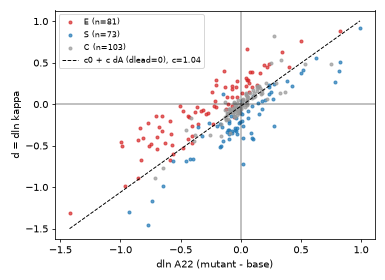

In [4]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display
p = pl.read_csv(R / "mutant_pairs.csv")
fig, ax = plt.subplots(figsize=(5.5, 4))
for arm, col in zip("ESC", ["tab:red", "tab:blue", "0.6"]):
    q = p.filter(pl.col("arm") == arm)
    ax.scatter(q["dA"], q["d"], s=10, c=col, alpha=.7, label=f"{arm} (n={q.height})")
x = np.linspace(p["dA"].min(), p["dA"].max(), 2)
ax.plot(x, r["intercept"] + r["c_dA"] * x, "k--", lw=1, label=f"c0 + c dA (dlead=0), c={r['c_dA']:.2f}")
ax.axhline(0, c="k", lw=.5); ax.axvline(0, c="k", lw=.5)
ax.set_xlabel("dln A22 (mutant - base)"); ax.set_ylabel("d = dln kappa"); ax.legend(fontsize=8)
fig.tight_layout(); out = EXP / "scratch" / "pairs.png"; out.parent.mkdir(exist_ok=True); fig.savefig(out, dpi=70); plt.close(fig)
display(Image(filename=str(out)))

This shows that E pairs (red) sit left of zero in dA (extension shrinks the pattern) and above the area line, while S pairs (blue) sit at dA ≈ 0 and below zero. It does **not** show that the slope-1 area line is structural: ln kappa contains ln A by construction and shares measurement noise with dA.

In [5]:
print((R / "mutants_describe.txt").read_text())

# POST HOC descriptive; cmd: uv run experiments/2026-10-16-kappa-leadrun-fresh/scripts/describe_mutants.py
## arm E by dlead (capped at 6)
shape: (4, 5)
┌───────┬─────┬───────────┬──────────┬───────────┐
│ dlead ┆ n   ┆ mean_d    ┆ sd_d     ┆ mean_dA   │
│ ---   ┆ --- ┆ ---       ┆ ---      ┆ ---       │
│ i64   ┆ u32 ┆ f64       ┆ f64      ┆ f64       │
╞═══════╪═════╪═══════════╪══════════╪═══════════╡
│ 1     ┆ 41  ┆ 0.039589  ┆ 0.41991  ┆ -0.130958 │
│ 2     ┆ 31  ┆ -0.133753 ┆ 0.263536 ┆ -0.402985 │
│ 3     ┆ 6   ┆ -0.427151 ┆ 0.679748 ┆ -0.741542 │
│ 4     ┆ 3   ┆ 0.025557  ┆ 0.189948 ┆ -0.455281 │
└───────┴─────┴───────────┴──────────┴───────────┘
## by arm x base_lead
shape: (14, 6)
┌─────┬───────────┬─────┬───────────┬──────────┬───────────┐
│ arm ┆ base_lead ┆ n   ┆ mean_d    ┆ sd_d     ┆ mean_dA   │
│ --- ┆ ---       ┆ --- ┆ ---       ┆ ---      ┆ ---       │
│ str ┆ i64       ┆ u32 ┆ f64       ┆ f64      ┆ f64       │
╞═════╪═══════════╪═════╪═══════════╪══════════╪════════

This post hoc table (written after seeing M1-M4) shows the area-adjusted residual: E +0.24, S -0.21, C -0.01, which is roughly symmetric and close to the cross-sectional 0.15-0.2 per step. It does **not** count as a registered test.

## Caveats and controls
- **Positive/negative controls.** Arm C (late flip, lead unchanged) gives d ≈ 0 and dA ≈ 0. The refit-on-shuffle null (A1) gives gain ≈ 0. The instrument identity check is exact on 30 duplicated rules. The kappa estimator itself is calibrated elsewhere (`notes/calibration.md`); nothing new was calibrated here.
- **Failed predictions:** L2, L4, L5, the A2 "within 0.05" part, M1 and M2. M3 held.
- **Selection:** only 53% of E mutants are kept and stationary, against 65-68% for S and C. Survivors only.
- **Definitional coupling:** kappa = B·A/P, so the c ≈ 1 area adjustment is partly mechanical. dA is a mediator, so b is a direct effect and E's mean d is the total effect.
- **Clustered pairs:** the pooled-regression CI ignores that up to 3 pairs share a base, so it is somewhat too narrow.
- **Rerun:** the first mutant launch died at 600/3336 runs and was rerun unchanged (NOTEBOOK 2026-10-18).

## What this changes, next steps, open questions
M1 and M2 both failed, and the README registered that this joint failure means the lead association is **not established as causal** at the single-flip scale. What remains is suggestive only: M3 and the area-adjusted b point the same way as the cross-sectional effect, but the E decomposition is post hoc and S lacks a composition control (README addendum 2026-10-18 20:15). The total effect is sign-mixed, because lengthening the lead also shrinks the pattern.
Next steps: a registered arm that flips an early letter with the lead unchanged (index k+1 or k+2), to separate lead from position; censoring or a larger board to bound E dropouts.
Open question: why does growing the leading R-run shrink A22 while shrinking it does not?